In [26]:
import pandas as pd
import scipy.stats
from matplotlib import gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.gridspec as gridspec
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from adjustText import adjust_text
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from collections import Counter
import torch
import os
import sys
from BWM.models.isometric_autoencoder import get_density_proxy
# Add project root to path
sys.path.append(os.path.abspath('../../'))
import torch.optim as optim
from BWM.bwm_functions import *
from BWM.models.isometric_autoencoder import SklearnIsometricAutoencoder

plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

# Set global plotting parameters for font size
tick_fontsize = 6
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': tick_fontsize,
    'ytick.labelsize': tick_fontsize,
    'legend.fontsize': 7,
    'figure.titlesize': 7
})

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


In [2]:
# directory_path = '../Data2'
# all_items = os.listdir(directory_path)
# eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]
# region = 'CP' # Caudoputamen
# pseudo_response_tensor, condition_matrix, neuron_eids = get_region_response_matrix(
#     eids=eids,
#     directory_path=directory_path,
#     region=region,
#     mapping='Beryl',
#     sigma=5,
#     n_steps=100,
#     threshold=1,
#     min_trials_per_condition=50,
#     n_pseudo=25,
#     conditions=['choice'],
#     event="stimOn_times",
#     filter_significant=False,
#     significance_threshold=0.
# )
pseudo_response_tensor = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/ResponseData/CP_pseudo_responses.npy')


In [3]:

def iso_ae_preprocessing(pseudo_response_tensor):
    """
    Preprocess neural responses intro response matrix (n x kt) for autoencoder.
    """
    response_tensor = np.mean(pseudo_response_tensor, axis=0)
    # Z-score and reshape
    response_tensor_norm = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (
                np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    response_matrix = response_tensor_norm.reshape(-1, response_tensor_norm.shape[2])
    X_transposed = response_matrix.T
    # Scale each row (neuron) to unit length
    row_norms = np.linalg.norm(X_transposed, axis=1, keepdims=True)
    X_pre_pca = X_transposed / (row_norms + 1e-8)
    return X_pre_pca


X_input = iso_ae_preprocessing(pseudo_response_tensor)

In [8]:
def calculate_msd_data(response_tensor):
    """
    Calculate Mean Standardized Derivative using finite differences.
    responses: (conditions, time, neurons)
    """
    z = (response_tensor - np.mean(response_tensor, axis=(0, 1), keepdims=True)) / (np.std(response_tensor, axis=(0, 1), keepdims=True) + 1e-8)
    #diff_responses = np.diff(response_tensor_norm, axis=1)
    speed= np.median(np.abs(np.diff(z,axis=1)),axis=(0,1))
    # Absolute standardized derivative (already standardized in the previous cell)
    # Mean over conditions and time and pseudo trials
   # msd = np.mean(np.abs(diff_responses), axis=(0,1))
    return speed

msd_data = calculate_msd_data(np.mean(pseudo_response_tensor, axis=0))

In [103]:
loc_density = get_density_proxy(X_input, k=50).numpy()

z_pca = PCA(n_components = 2).fit_transform(X_input)
pca_density = get_density_proxy(z_pca, k=50).numpy()
z_tsne = TSNE(perplexity = 500).fit_transform(X_input)
tsne_density = get_density_proxy(z_tsne, k=50).numpy()
z_umap = umap.UMAP(n_neighbors=500).fit_transform(X_input)
umap_density = get_density_proxy(z_umap, k=50).numpy()
z_dens = umap.UMAP(dens_lambda=1, densmap=True, n_neighbors=500).fit_transform(X_input)
dens_density = get_density_proxy(z_dens, k=50).numpy()

# Calculate Spearman correlation before monotonic transformation
rho, _ = scipy.stats.spearmanr(dens_density, loc_density)

# Monotonic transformation of loc_density to match dens_density
loc_density_sorted_indices = np.argsort(loc_density)
dens_density_sorted = np.sort(dens_density)
loc_density_matched = np.zeros_like(loc_density)
loc_density_matched[loc_density_sorted_indices] = dens_density_sorted
loc_density = loc_density_matched



In [104]:
sorted_msd_index = np.argsort(msd_data)
neurons = sorted_msd_index[[0,10,500,1000]]
neurons

array([ 4057,  7714, 11186,   421])

/var/folders/9_/yjc4d8zx4tj6kw6h4xgj4zd80000gn/T/ipykernel_45305/4228144049.py:83: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


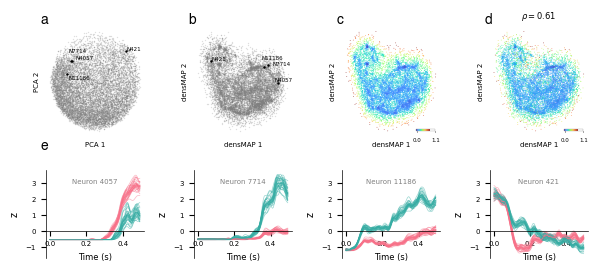

In [125]:
fig = plt.figure(figsize=(7, 3))
gs = gridspec.GridSpec(2, 4, wspace=.5, hspace=.35, height_ratios=[1, .8])

# Original first row (now Row 0)
ax1 = plt.subplot(gs[0, 0])
ax2 = plt.subplot(gs[0, 1])
ax3 = plt.subplot(gs[0, 2])
ax4 = plt.subplot(gs[0, 3])

# Original second row (now Row 1)
ax5 = plt.subplot(gs[1, 0])
ax6 = plt.subplot(gs[1, 1])
ax7 = plt.subplot(gs[1, 2])
ax8 = plt.subplot(gs[1, 3])

# Original Row 0 (now Row 0) plotting (Colored by local density of the projection)
for ax, z_proj, density_proj, label in zip(
    [ax1, ax2, ax3, ax4],
    [z_pca, z_dens, z_dens, z_dens],
    [pca_density, dens_density, dens_density, loc_density],
    ['PCA', 'densMAP', 'densMAP', 'densMAP']
):
    if ax in [ax1, ax2]:
        im = ax.scatter(z_proj[:, 0], z_proj[:, 1], s=1, c='gray', alpha=.25, lw=0)
    else:
        im = ax.scatter(z_proj[:, 0], z_proj[:, 1], s=.35, c=density_proj, cmap='turbo', alpha=.75, lw=0,vmax = np.max(density_proj)-.3, vmin = np.min(density_proj)-0.075)
    
    ax.set_xlabel(f'{label} 1', fontsize=5)
    ax.set_ylabel(f'{label} 2', fontsize=5)
    
    if ax == ax4:
        ax.set_title(fr'$\rho = {rho:.2f}$', fontsize=6)
    0
    if ax not in [ax1, ax2]:
        cax = inset_axes(ax, width="20%", height="1.5%", loc="lower right", borderpad=0.5)
        cb = fig.colorbar(im, cax=cax, orientation="horizontal")
        cb.outline.set_linewidth(0.1)
        cb.set_ticks([density_proj.min(), density_proj.max()])
        cb.ax.set_xticklabels([f'{density_proj.min():.1f}', f'{density_proj.max():.1f}'])
        cax.xaxis.set_tick_params(size=1, width=.5, labelsize=4)
    else:
        # Add markers and labels for specific neurons in panels a and b
        texts = []
        for i, neuron_idx in enumerate(neurons):
            ax.scatter(z_proj[neuron_idx, 0], z_proj[neuron_idx, 1], s=5, c='k', marker='.', lw=0.5)
            t = ax.text(z_proj[neuron_idx, 0], z_proj[neuron_idx, 1], f'N{neuron_idx}', fontsize=4, color='k')
            texts.append(t)
        adjust_text(texts, ax=ax)

# Third row
z = (pseudo_response_tensor - np.mean(pseudo_response_tensor, axis=(0, 1,2), keepdims=True)) / (
                np.std(pseudo_response_tensor, axis=(0, 1,2), keepdims=True) + 1e-8)

rows = []
for trial in range(z.shape[0]):
    for condition in range(z.shape[1]):
        for t in range(z.shape[2]):
            for neuron in neurons:
                rows.append({'trial': trial,
                             't': t*.005,
                             'condition': condition,
                             'neuron': neuron,
                             'z': z[trial,condition,t,neuron],})
df = pd.DataFrame(rows)

y_min_second_row = df['z'].min()
y_max_second_row = df['z'].max()
pad = 0.05 * (y_max_second_row - y_min_second_row)
y_min_second_row -= pad
y_max_second_row += pad

for i, ax in enumerate([ax5, ax6, ax7, ax8]):
    neuron_idx = neurons[i]
    # Plot individual trials
    sns.lineplot(data=df[df.neuron==neuron_idx], ax=ax, x='t', y='z', hue='condition', units='trial', estimator=None, legend=False, lw=0.5, alpha=0.5, palette='husl')
    # Plot mean across trials
    sns.lineplot(data=df[df.neuron==neuron_idx], ax=ax, x='t', y='z', hue='condition', legend=False, lw=.5, alpha=1.0, palette='husl')
    ax.text(0.5, 0.85, f"Neuron {neuron_idx}", transform=ax.transAxes, ha='center', fontsize=5, alpha=.5)
    ax.set_xlabel('Time (s)', fontsize=6)
    ax.tick_params(axis='both', which='major', labelsize=5)
    ax.set_ylim(y_min_second_row, y_max_second_row)

plt.tight_layout()

for ax in [ax1, ax2, ax3, ax4]:
    for spine in ax.spines.values():
        spine.set_visible(False)

    # 2. Hide the tick marks and tick numbers
    ax.set_xticks([])
    ax.set_yticks([])

for ax in [ax5,ax6,ax7,ax8]:
    ax.spines['bottom'].set_position(('data', 0))
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)



ax1.text(-0.05, 1., 'a', transform=ax1.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax2.text(-0.05, 1., 'b', transform=ax2.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax3.text(-0.05, 1., 'c', transform=ax3.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')
ax4.text(-0.05, 1., 'd', transform=ax4.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')

ax5.text(-0.05, 1.2, 'e', transform=ax5.transAxes,
         fontsize=10, fontweight='bold', va='bottom', ha='left',fontname = 'Helvetica')

    # 3. Add your labels normally

plt.savefig('projectioncomparison.png', dpi=300, bbox_inches='tight')

In [38]:
pwd

'/Users/cl1704/PycharmProjects/embedding_dimension/BWM/Notebooks'